# Week 1.2: LLM Big Picture & Anatomy for Digital Twins

## Learning Objectives
- Understand the overall architecture of LLMs
- Learn about tokens, tokenization, and embeddings
- See how different components work together
- Apply these concepts to building a language-enabled digital twin

## Key Insight
> "Know the different bits of the LLM architecture and how they work together to generate outputs."

## Digital Twin Context
Today we'll enhance our digital twin with language understanding capabilities. By the end, your digital twin will:
- Convert text to numerical representations
- Understand word relationships and context
- Process sequences of information

In [1]:
# Import required libraries
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter, defaultdict
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import re

# Set style
sns.set_style('whitegrid')
np.random.seed(42)

print("✅ Libraries loaded successfully!")

✅ Libraries loaded successfully!


---
## Part 1: Tokenization - Breaking Text into Pieces

Before an LLM can process text, it needs to convert words into tokens.

### 1.1 Simple Word Tokenization

In [2]:
def simple_tokenize(text):
    """
    Basic tokenization: split text into words.

    Args:
        text: Input string

    Returns:
        list: Tokens
    """
    # Convert to lowercase and split
    text = text.lower()
    # Remove punctuation and split
    tokens = re.findall(r'\b\w+\b', text)
    return tokens

# Example: Digital twin's user description
user_description = """
I love running in the morning before work. Coffee is essential.
I enjoy reading science fiction and coding in Python.
Weekends are for family time and outdoor activities.
"""

tokens = simple_tokenize(user_description)
print("Original text:")
print(user_description)
print(f"\nTokens ({len(tokens)} total):")
print(tokens[:20], "...")  # Show first 20

# Count token frequencies
token_counts = Counter(tokens)
print("\nMost common tokens:")
for token, count in token_counts.most_common(10):
    print(f"  {token}: {count}")

Original text:

I love running in the morning before work. Coffee is essential. 
I enjoy reading science fiction and coding in Python. 
Weekends are for family time and outdoor activities.


Tokens (28 total):
['i', 'love', 'running', 'in', 'the', 'morning', 'before', 'work', 'coffee', 'is', 'essential', 'i', 'enjoy', 'reading', 'science', 'fiction', 'and', 'coding', 'in', 'python'] ...

Most common tokens:
  i: 2
  in: 2
  and: 2
  love: 1
  running: 1
  the: 1
  morning: 1
  before: 1
  work: 1
  coffee: 1


### 🎯 Exercise 1.1 (Easy): Personal Tokenization

**Task**: Write a short description of yourself (3-4 sentences) and tokenize it.

**Questions**:
1. How many unique tokens do you have?
2. What are your most frequent tokens?
3. How does tokenization help the digital twin understand you?

In [5]:
# YOUR CODE HERE
my_description = """
I am a software engineer, and a language ethusiast, for fun I play tennis and chess
"""

# Tokenize and analyze
my_tokens = simple_tokenize(my_description)

# Your analysis:
print(f"Total tokens: {len(my_tokens)}")
print(f"Unique tokens: {len(set(my_tokens))}")
# Add more analysis
tokens = Counter(my_tokens)
print("\nMost common tokens:")
for token, count in tokens.most_common(10):
    print(f"  {token}: {count}")

Total tokens: 16
Unique tokens: 13

Most common tokens:
  i: 2
  a: 2
  and: 2
  am: 1
  software: 1
  engineer: 1
  language: 1
  ethusiast: 1
  for: 1
  fun: 1


### 1.2 Subword Tokenization (BPE-like)

Real LLMs use subword tokenization to handle rare words and morphology.

In [6]:
class SimpleTokenizer:
    """Simple subword tokenizer inspired by BPE."""

    def __init__(self, vocab_size=100):
        self.vocab_size = vocab_size
        self.word_to_id = {}
        self.id_to_word = {}
        self.subword_vocab = []

    def build_vocab(self, texts):
        """
        Build vocabulary from texts.

        Args:
            texts: List of text strings
        """
        # Get all words
        all_words = []
        for text in texts:
            all_words.extend(simple_tokenize(text))

        # Count frequencies
        word_counts = Counter(all_words)

        # Take most common words
        most_common = word_counts.most_common(self.vocab_size)

        # Build vocabulary
        special_tokens = ['<PAD>', '<UNK>', '<START>', '<END>']
        self.word_to_id = {word: i for i, word in enumerate(special_tokens)}

        for i, (word, count) in enumerate(most_common):
            self.word_to_id[word] = i + len(special_tokens)

        self.id_to_word = {i: word for word, i in self.word_to_id.items()}

        print(f"Vocabulary built: {len(self.word_to_id)} tokens")

    def encode(self, text):
        """
        Convert text to token IDs.

        Args:
            text: Input string

        Returns:
            list: Token IDs
        """
        tokens = simple_tokenize(text)
        unk_id = self.word_to_id['<UNK>']
        return [self.word_to_id.get(token, unk_id) for token in tokens]

    def decode(self, token_ids):
        """
        Convert token IDs back to text.

        Args:
            token_ids: List of token IDs

        Returns:
            str: Decoded text
        """
        tokens = [self.id_to_word.get(id, '<UNK>') for id in token_ids]
        # Filter special tokens
        tokens = [t for t in tokens if not t.startswith('<')]
        return ' '.join(tokens)

# Build tokenizer for digital twin
training_texts = [
    user_description,
    "I prefer tea over coffee in the afternoon",
    "Running helps me stay focused and energized",
    "Python is my favorite programming language",
    "I love spending time with family on weekends",
]

tokenizer = SimpleTokenizer(vocab_size=50)
tokenizer.build_vocab(training_texts)

# Test encoding and decoding
test_text = "I love running and coding in Python"
encoded = tokenizer.encode(test_text)
decoded = tokenizer.decode(encoded)

print(f"\nOriginal: {test_text}")
print(f"Encoded: {encoded}")
print(f"Decoded: {decoded}")

Vocabulary built: 45 tokens

Original: I love running and coding in Python
Encoded: [4, 7, 8, 6, 24, 5, 12]
Decoded: i love running and coding in python


### 🎯 Exercise 1.2 (Intermediate): Vocabulary Analysis

**Task**: Analyze what happens with different vocabulary sizes.

**Questions**:
1. What happens when you use a very small vocabulary (vocab_size=10)?
2. How many unknown tokens do you get?
3. What's the trade-off between vocabulary size and coverage?

In [13]:

# Experiment with different vocabulary sizes

vocab_sizes = [10, 20, 50, 70, 90, 100, 5]

test_texts = [
    "I love running and programming",
    "Coffee is essential for productivity",
    "Weekend activities include hiking and reading",
]

results = []

for size in vocab_sizes:
    # Create tokenizer using the current vocabulary size
    tokenizer = SimpleTokenizer(vocab_size=size)
    tokenizer.build_vocab(training_texts)

    # Count unknown tokens across all test texts
    unknown_count = 0

    for text in test_texts:
        encoded = tokenizer.encode(text)
        unknown_count += encoded.count(tokenizer.word_to_id["<UNK>"])

    # Store results
    results.append((size, unknown_count))

    # Test encoding and decoding
    test_text = "I love running and coding in Python"
    encoded = tokenizer.encode(test_text)
    decoded = tokenizer.decode(encoded)

    print(f"\nVocabulary size: {size}")
    print(f"Original: {test_text}")
    print(f"Encoded: {encoded}")
    print(f"Decoded: {decoded}")
    print(f"Unknown tokens: {unknown_count}")

# Display results
print("\nResults (vocabulary size, unknown token count):")
print(results)


Vocabulary built: 14 tokens

Vocabulary size: 10
Original: I love running and coding in Python
Encoded: [4, 7, 8, 6, 1, 5, 12]
Decoded: i love running and in python
Unknown tokens: 9
Vocabulary built: 24 tokens

Vocabulary size: 20
Original: I love running and coding in Python
Encoded: [4, 7, 8, 6, 1, 5, 12]
Decoded: i love running and in python
Unknown tokens: 7
Vocabulary built: 45 tokens

Vocabulary size: 50
Original: I love running and coding in Python
Encoded: [4, 7, 8, 6, 24, 5, 12]
Decoded: i love running and coding in python
Unknown tokens: 4
Vocabulary built: 45 tokens

Vocabulary size: 70
Original: I love running and coding in Python
Encoded: [4, 7, 8, 6, 24, 5, 12]
Decoded: i love running and coding in python
Unknown tokens: 4
Vocabulary built: 45 tokens

Vocabulary size: 90
Original: I love running and coding in Python
Encoded: [4, 7, 8, 6, 24, 5, 12]
Decoded: i love running and coding in python
Unknown tokens: 4
Vocabulary built: 45 tokens

Vocabulary size: 100
Original: I

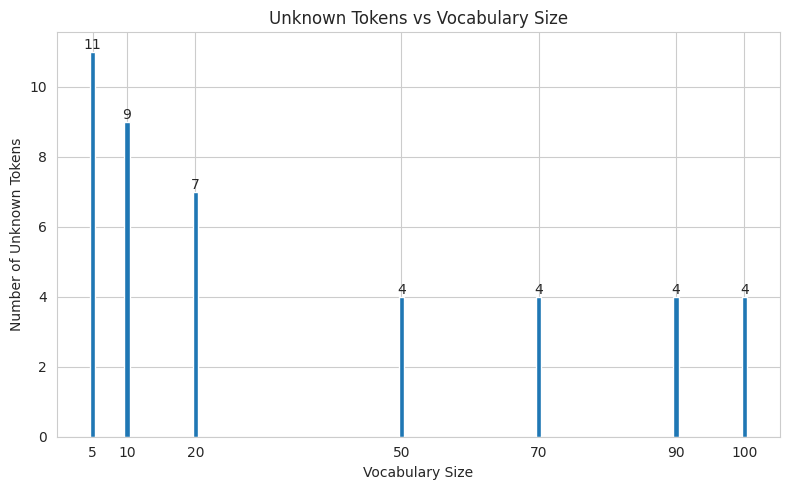

In [14]:

import matplotlib.pyplot as plt

# Extract data from results
vocab_sizes_result = [item[0] for item in results]
unknown_counts = [item[1] for item in results]

# Create bar chart
plt.figure(figsize=(8, 5))
bars = plt.bar(vocab_sizes_result, unknown_counts)

plt.title("Unknown Tokens vs Vocabulary Size")
plt.xlabel("Vocabulary Size")
plt.ylabel("Number of Unknown Tokens")
plt.xticks(vocab_sizes_result)

# Display values above each bar
for bar, count in zip(bars, unknown_counts):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        str(count),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


---
## Part 2: Embeddings - Giving Meaning to Tokens

Embeddings convert tokens into dense vectors that capture semantic meaning.

### 2.1 Creating Simple Embeddings

In [15]:
class SimpleEmbedding:
    """Simple word embedding layer."""

    def __init__(self, vocab_size, embedding_dim):
        """
        Initialize embedding matrix.

        Args:
            vocab_size: Size of vocabulary
            embedding_dim: Dimension of embedding vectors
        """
        self.vocab_size = vocab_size
        self.embedding_dim = embedding_dim
        # Initialize with random values
        self.embeddings = np.random.randn(vocab_size, embedding_dim) * 0.1

    def embed(self, token_ids):
        """
        Get embeddings for token IDs.

        Args:
            token_ids: List of token IDs

        Returns:
            np.array: Embedding vectors
        """
        return self.embeddings[token_ids]

    def similarity(self, id1, id2):
        """
        Calculate cosine similarity between two tokens.

        Args:
            id1, id2: Token IDs

        Returns:
            float: Cosine similarity
        """
        vec1 = self.embeddings[id1]
        vec2 = self.embeddings[id2]

        # Cosine similarity
        dot_product = np.dot(vec1, vec2)
        norm1 = np.linalg.norm(vec1)
        norm2 = np.linalg.norm(vec2)

        return dot_product / (norm1 * norm2)

# Create embeddings for our vocabulary
vocab_size = len(tokenizer.word_to_id)
embedding_dim = 16  # Small dimension for visualization

embedding_layer = SimpleEmbedding(vocab_size, embedding_dim)

# Test with some words
test_words = ['running', 'coding', 'coffee', 'python', 'family']
print("Word embeddings:")
for word in test_words:
    if word in tokenizer.word_to_id:
        token_id = tokenizer.word_to_id[word]
        embedding = embedding_layer.embed([token_id])[0]
        print(f"\n{word} (ID: {token_id}):")
        print(f"  Embedding (first 5 dims): {embedding[:5]}")
        print(f"  Norm: {np.linalg.norm(embedding):.3f}")

Word embeddings:

running (ID: 8):
  Embedding (first 5 dims): [ 0.00996514 -0.05034757 -0.15506634  0.0068563  -0.10623037]
  Norm: 0.381


### 2.2 Training Embeddings with Context

Embeddings learn meaning from co-occurrence patterns (Word2Vec style).

In [16]:
def train_embeddings(tokenizer, texts, embedding_dim=16, window_size=2,
                     learning_rate=0.01, epochs=100):
    """
    Train embeddings using skip-gram approach.

    Args:
        tokenizer: Tokenizer instance
        texts: List of training texts
        embedding_dim: Dimension of embeddings
        window_size: Context window size
        learning_rate: Learning rate
        epochs: Number of training epochs

    Returns:
        SimpleEmbedding: Trained embedding layer
    """
    vocab_size = len(tokenizer.word_to_id)
    embeddings = SimpleEmbedding(vocab_size, embedding_dim)

    # Create training pairs (center word, context word)
    training_pairs = []
    for text in texts:
        token_ids = tokenizer.encode(text)
        for i, center_id in enumerate(token_ids):
            # Get context window
            start = max(0, i - window_size)
            end = min(len(token_ids), i + window_size + 1)
            context_ids = [token_ids[j] for j in range(start, end) if j != i]
            for context_id in context_ids:
                training_pairs.append((center_id, context_id))

    print(f"Training on {len(training_pairs)} word pairs...")

    # Simple training loop
    for epoch in range(epochs):
        total_loss = 0
        np.random.shuffle(training_pairs)

        for center_id, context_id in training_pairs:
            # Get embeddings
            center_emb = embeddings.embeddings[center_id]
            context_emb = embeddings.embeddings[context_id]

            # Calculate similarity
            similarity = np.dot(center_emb, context_emb)

            # Gradient descent (simplified)
            gradient = context_emb - similarity * center_emb
            embeddings.embeddings[center_id] += learning_rate * gradient

            total_loss += (1 - similarity) ** 2

        if epoch % 20 == 0:
            avg_loss = total_loss / len(training_pairs)
            print(f"Epoch {epoch}: Loss = {avg_loss:.4f}")

    return embeddings

# Train embeddings
trained_embeddings = train_embeddings(tokenizer, training_texts,
                                     embedding_dim=16, epochs=100)

print("\n✅ Embeddings trained!")

Training on 198 word pairs...
Epoch 0: Loss = 0.6768
Epoch 20: Loss = 0.0141
Epoch 40: Loss = 0.0002
Epoch 60: Loss = 0.0000
Epoch 80: Loss = 0.0000

✅ Embeddings trained!


In [17]:
# Test similarity after training
def find_similar_words(word, tokenizer, embeddings, top_k=5):
    """
    Find most similar words to given word.

    Args:
        word: Query word
        tokenizer: Tokenizer instance
        embeddings: Embedding layer
        top_k: Number of similar words to return

    Returns:
        list: Similar words with similarities
    """
    if word not in tokenizer.word_to_id:
        return None

    word_id = tokenizer.word_to_id[word]
    word_emb = embeddings.embeddings[word_id]

    # Calculate similarities with all words
    similarities = []
    for other_word, other_id in tokenizer.word_to_id.items():
        if other_word.startswith('<') or other_id == word_id:
            continue
        sim = embeddings.similarity(word_id, other_id)
        similarities.append((other_word, sim))

    # Sort by similarity
    similarities.sort(key=lambda x: x[1], reverse=True)
    return similarities[:top_k]

# Test with some words
test_words = ['running', 'python', 'coffee', 'love']
for word in test_words:
    similar = find_similar_words(word, tokenizer, trained_embeddings)
    if similar:
        print(f"\nWords similar to '{word}':")
        for similar_word, sim in similar:
            print(f"  {similar_word}: {sim:.3f}")


Words similar to 'running':
  i: 1.000
  in: 1.000
  love: 1.000
  and: 1.000

Words similar to 'love':
  i: 1.000
  running: 1.000
  in: 1.000
  and: 1.000


### 🎯 Exercise 2.1 (Intermediate): Embedding Visualization

**Task**: Visualize word embeddings in 2D space using dimensionality reduction.

**Steps**:
1. Use PCA or t-SNE to reduce embeddings to 2D
2. Plot the words
3. Identify clusters of related words

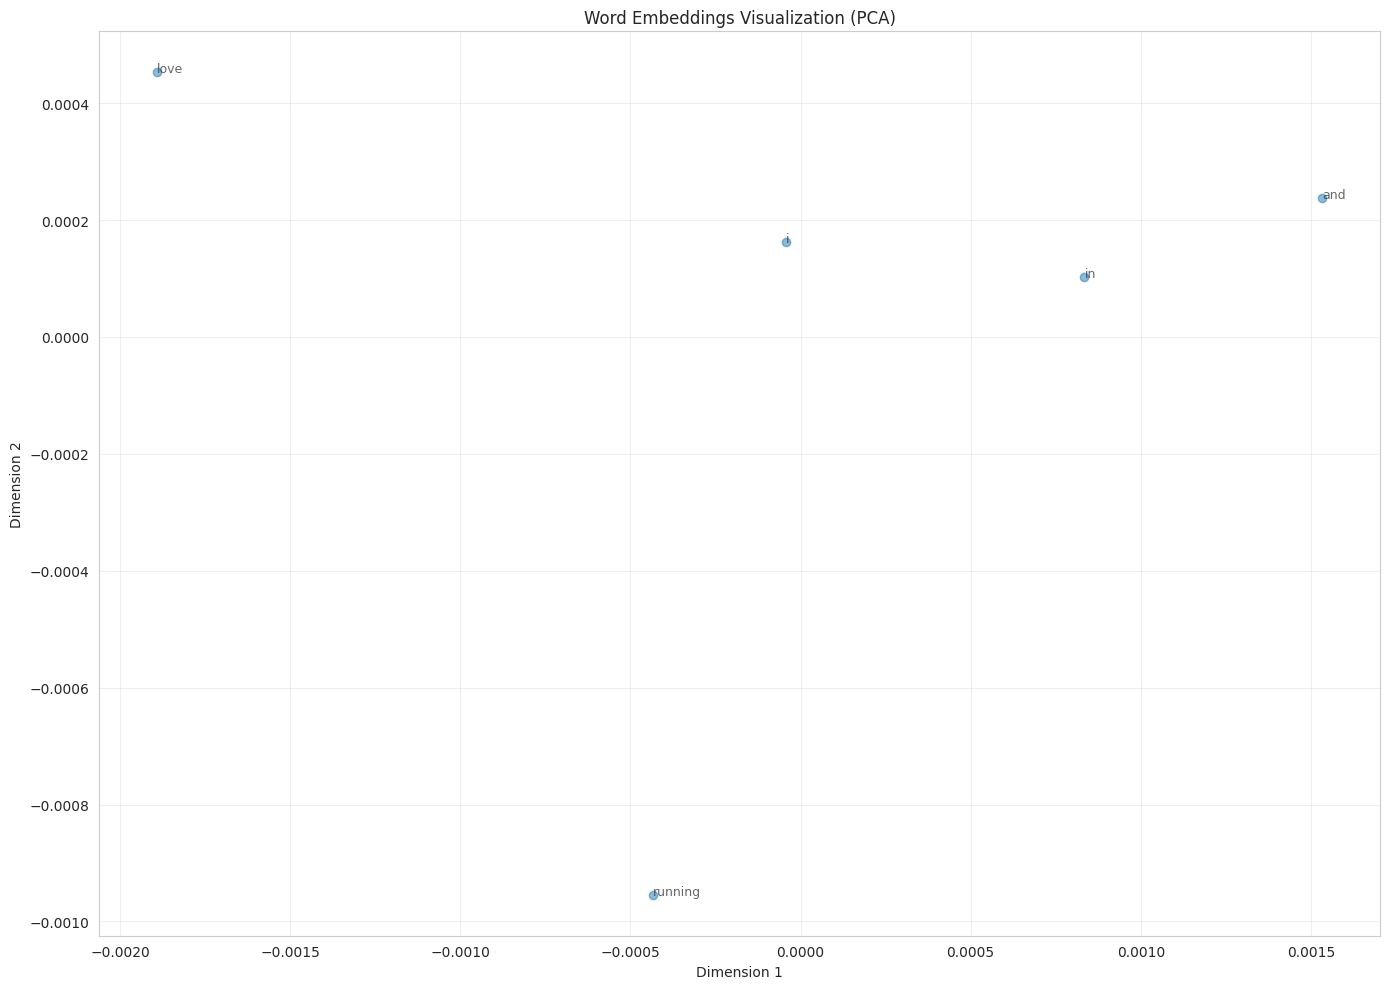

In [18]:
# YOUR CODE HERE
def visualize_embeddings(tokenizer, embeddings, method='pca'):
    """
    Visualize embeddings in 2D.

    Args:
        tokenizer: Tokenizer instance
        embeddings: Embedding layer
        method: 'pca' or 'tsne'
    """
    # Get all embeddings (excluding special tokens)
    words = []
    vectors = []

    for word, idx in tokenizer.word_to_id.items():
        if not word.startswith('<'):
            words.append(word)
            vectors.append(embeddings.embeddings[idx])

    vectors = np.array(vectors)

    # Reduce dimensionality
    if method == 'pca':
        reducer = PCA(n_components=2)
    else:
        reducer = TSNE(n_components=2, random_state=42)

    coords_2d = reducer.fit_transform(vectors)

    # Plot
    plt.figure(figsize=(14, 10))
    plt.scatter(coords_2d[:, 0], coords_2d[:, 1], alpha=0.5)

    # Annotate words
    for i, word in enumerate(words[:30]):  # Show first 30 to avoid clutter
        plt.annotate(word, (coords_2d[i, 0], coords_2d[i, 1]),
                    fontsize=9, alpha=0.7)

    plt.title(f'Word Embeddings Visualization ({method.upper()})')
    plt.xlabel('Dimension 1')
    plt.ylabel('Dimension 2')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

# Visualize
visualize_embeddings(tokenizer, trained_embeddings, method='pca')

---
## Part 3: LLM Architecture Overview

Now let's see how these components fit into the bigger picture.

### 3.1 The LLM Pipeline

In [19]:
class SimpleLLMPipeline:
    """
    Simplified LLM pipeline showing major components.
    """

    def __init__(self, tokenizer, embeddings):
        self.tokenizer = tokenizer
        self.embeddings = embeddings
        self.processing_steps = []

    def process(self, text, verbose=True):
        """
        Process text through the pipeline.

        Args:
            text: Input text
            verbose: Print intermediate steps

        Returns:
            dict: Processing results
        """
        results = {}

        # Step 1: Tokenization
        if verbose:
            print("Step 1: Tokenization")
            print("  Input text:", text)

        tokens = simple_tokenize(text)
        token_ids = self.tokenizer.encode(text)

        if verbose:
            print(f"  Tokens: {tokens}")
            print(f"  Token IDs: {token_ids}")

        results['tokens'] = tokens
        results['token_ids'] = token_ids

        # Step 2: Embedding
        if verbose:
            print("\nStep 2: Embedding")

        embedded = self.embeddings.embed(token_ids)

        if verbose:
            print(f"  Embedding shape: {embedded.shape}")
            print(f"  (sequence_length={len(token_ids)}, embedding_dim={embedded.shape[1]})")

        results['embeddings'] = embedded

        # Step 3: Attention (simplified - just mean pooling)
        if verbose:
            print("\nStep 3: Contextual Processing (Simplified)")

        # Simple mean pooling as placeholder
        contextualized = np.mean(embedded, axis=0)

        if verbose:
            print(f"  Contextualized representation shape: {contextualized.shape}")

        results['contextualized'] = contextualized

        # Step 4: Output projection (simplified)
        if verbose:
            print("\nStep 4: Output Generation (Simplified)")
            print("  → In real LLMs, this produces probability distribution over vocabulary")

        return results

# Create pipeline
pipeline = SimpleLLMPipeline(tokenizer, trained_embeddings)

# Test with digital twin input
test_input = "I love running and coding"
print("=" * 60)
print("PROCESSING THROUGH LLM PIPELINE")
print("=" * 60 + "\n")

results = pipeline.process(test_input, verbose=True)

print("\n" + "=" * 60)
print("✅ Processing complete!")
print("=" * 60)

PROCESSING THROUGH LLM PIPELINE

Step 1: Tokenization
  Input text: I love running and coding
  Tokens: ['i', 'love', 'running', 'and', 'coding']
  Token IDs: [4, 7, 8, 6, 1]

Step 2: Embedding
  Embedding shape: (5, 16)
  (sequence_length=5, embedding_dim=16)

Step 3: Contextual Processing (Simplified)
  Contextualized representation shape: (16,)

Step 4: Output Generation (Simplified)
  → In real LLMs, this produces probability distribution over vocabulary

✅ Processing complete!


### 🎯 Exercise 3.1 (Conceptual): Architecture Understanding

**Questions**:

1. Why is tokenization necessary before embedding?
2. What information is captured in embeddings?
3. What would happen if we skipped the embedding step and used one-hot encoding instead?
4. How does sequence length affect computational cost?
5. In a real LLM, what happens after the "contextual processing" step?

Write your answers below:

**Your Answers:**

1. Why tokenization is necessary: Neural networks cannot process raw, unstructured text strings directly. Tokenization breaks text down into discrete, manageable units (subwords or words) and maps them to numerical IDs that embeddings can transform into dense vectors.
   -

2. Information in embeddings: Semantic meaning, syntactic properties, and contextual relationships
   -

3. One-hot encoding vs embeddings: It would cause extreme memory and computational inefficiency due to massive, sparse vectors. More importantly, it would fail to capture semantic relationships, as all one-hot vectors are orthogonal (equidistant from one another), meaning the model couldn't inherently understand word similarities.
   -

4. Sequence length impact: In standard Transformer models, computational cost and memory usage scale quadratically ($O(N^2)$) with sequence length due to the self-attention mechanism, meaning longer texts require significantly more processing power and time.
   -

5. After contextual processing: The final hidden states are passed through an output layer (often called the language model head) which projects the representations back onto the vocabulary space to generate probability distributions for the next token.
   -

### 3.2 Comparing Different Embedding Dimensions

In [20]:
# Experiment with different embedding dimensions
dimensions = [4, 8, 16, 32]

print("Comparing embedding dimensions:\n")
for dim in dimensions:
    emb = SimpleEmbedding(vocab_size, dim)

    # Calculate memory usage
    memory_mb = (vocab_size * dim * 4) / (1024 * 1024)  # 4 bytes per float

    print(f"Dimension {dim}:")
    print(f"  Parameters: {vocab_size * dim:,}")
    print(f"  Memory: {memory_mb:.2f} MB")
    print(f"  Expressiveness: {'Low' if dim < 16 else 'Medium' if dim < 64 else 'High'}")
    print()

Comparing embedding dimensions:

Dimension 4:
  Parameters: 36
  Memory: 0.00 MB
  Expressiveness: Low

Dimension 8:
  Parameters: 72
  Memory: 0.00 MB
  Expressiveness: Low

Dimension 16:
  Parameters: 144
  Memory: 0.00 MB
  Expressiveness: Medium

Dimension 32:
  Parameters: 288
  Memory: 0.00 MB
  Expressiveness: Medium



### 🎯 Exercise 3.2 (Advanced): Build a Mini Language Model

**Task**: Create a simple language model that can predict the next word.

**Requirements**:
1. Use the tokenizer and embeddings we created
2. Implement a simple prediction mechanism
3. Test with different input sequences
4. Measure prediction accuracy

**Hint**: You can use the embeddings to find the most similar word to a context representation.

In [ ]:
# YOUR CODE HERE
class MiniLanguageModel:
    """
    Simple language model for next word prediction.
    """

    def __init__(self, tokenizer, embeddings):
        self.tokenizer = tokenizer
        self.embeddings = embeddings
        # Build context patterns from training data
        self.context_patterns = self._build_patterns()

    def _build_patterns(self):
        """Build context → next word patterns from training data."""
        # YOUR CODE HERE
        pass

    def predict_next_word(self, context):
        """
        Predict the most likely next word.

        Args:
            context: String of context words

        Returns:
            str: Predicted next word
        """
        # YOUR CODE HERE
        pass

    def generate_sequence(self, start_text, num_words=5):
        """
        Generate a sequence of words.

        Args:
            start_text: Starting context
            num_words: Number of words to generate

        Returns:
            str: Generated text
        """
        # YOUR CODE HERE
        pass

# Test your model
# model = MiniLanguageModel(tokenizer, trained_embeddings)
# prediction = model.predict_next_word("I love")
# print(f"Next word prediction: {prediction}")


In [21]:

import numpy as np
from collections import defaultdict, Counter


class MiniLanguageModel:
    """
    Simple next-word language model using context patterns
    and word embeddings.
    """

    def __init__(self, tokenizer, embeddings, training_texts=None,
                 context_window=3):
        self.tokenizer = tokenizer
        self.embeddings = embeddings
        self.context_window = context_window

        # Support NumPy arrays and PyTorch embedding tensors
        matrix = embeddings.embeddings
        if hasattr(matrix, "detach"):
            matrix = matrix.detach().cpu().numpy()

        self.embedding_matrix = np.asarray(matrix, dtype=float)

        # Map token IDs back to words
        self.id_to_word = {
            idx: word
            for word, idx in tokenizer.word_to_id.items()
        }

        # Use training_texts from the notebook if not supplied
        if training_texts is None:
            if "training_texts" not in globals():
                raise ValueError(
                    "Provide training_texts or define it in your notebook."
                )
            training_texts = globals()["training_texts"]

        self.context_patterns = self._build_patterns(training_texts)

    def _build_patterns(self, training_texts):
        """Build context -> next-word frequency patterns."""

        patterns = defaultdict(Counter)

        for text in training_texts:
            token_ids = self.tokenizer.encode(text)

            # Learn patterns of different context lengths
            for i in range(1, len(token_ids)):
                next_id = token_ids[i]

                # Ignore special tokens as prediction targets
                next_word = self.id_to_word.get(next_id, "<UNK>")
                if next_word.startswith("<"):
                    continue

                for length in range(
                    1, min(self.context_window, i) + 1
                ):
                    context = tuple(token_ids[i - length:i])
                    patterns[context][next_id] += 1

        return patterns

    def _ids_to_text(self, token_ids):
        """Convert token IDs into a context string."""
        return " ".join(
            self.id_to_word.get(idx, "<UNK>")
            for idx in token_ids
        )

    def _embedding_fallback(self, context_ids):
        """
        Find the word embedding most similar to the average
        embedding of the context.
        """
        valid_ids = [
            idx for idx in context_ids
            if 0 <= idx < len(self.embedding_matrix)
        ]

        if not valid_ids:
            return "<UNK>"

        context_vector = self.embedding_matrix[valid_ids].mean(axis=0)

        context_norm = np.linalg.norm(context_vector)
        if context_norm == 0:
            return "<UNK>"

        # Cosine similarity between context and vocabulary vectors
        norms = np.linalg.norm(self.embedding_matrix, axis=1)
        denominator = norms * context_norm

        similarities = np.full(len(norms), -np.inf)
        valid = denominator > 0

        similarities[valid] = (
            self.embedding_matrix[valid] @ context_vector
        ) / denominator[valid]

        # Avoid predicting a word already in the context when possible
        for idx in set(valid_ids):
            if idx < len(similarities):
                similarities[idx] = -np.inf

        # Exclude special tokens
        for idx, word in self.id_to_word.items():
            if word.startswith("<") and idx < len(similarities):
                similarities[idx] = -np.inf

        if not np.isfinite(similarities).any():
            return "<UNK>"

        best_id = int(np.argmax(similarities))
        return self.id_to_word.get(best_id, "<UNK>")

    def predict_next_word(self, context):
        """
        Predict the next word from a context string.
        """
        context_ids = self.tokenizer.encode(context)

        if not context_ids:
            return "<UNK>"

        # Try the longest matching context first
        max_length = min(self.context_window, len(context_ids))

        for length in range(max_length, 0, -1):
            key = tuple(context_ids[-length:])

            if key in self.context_patterns:
                # Choose the most frequently observed next word
                next_id = self.context_patterns[key].most_common(1)[0][0]
                return self.id_to_word.get(next_id, "<UNK>")

        # If no pattern matches, use embedding similarity
        return self._embedding_fallback(context_ids)

    def generate_sequence(self, start_text, num_words=5):
        """Generate text by repeatedly predicting the next word."""

        words = start_text.split()

        for _ in range(num_words):
            context = " ".join(words[-self.context_window:])
            next_word = self.predict_next_word(context)

            if next_word == "<UNK>":
                break

            words.append(next_word)

        return " ".join(words)


def evaluate_accuracy(model, test_texts):
    """
    Evaluate next-word accuracy on test sequences.

    Each prediction uses preceding words as context.
    """
    correct = 0
    total = 0

    for text in test_texts:
        token_ids = model.tokenizer.encode(text)

        for i in range(1, len(token_ids)):
            target_id = token_ids[i]
            target_word = model.id_to_word.get(target_id, "<UNK>")

            if target_word.startswith("<"):
                continue

            start = max(0, i - model.context_window)
            context_ids = token_ids[start:i]
            context = model._ids_to_text(context_ids)

            prediction = model.predict_next_word(context)

            if prediction == target_word:
                correct += 1

            total += 1

    accuracy = correct / total if total else 0.0

    print(f"Correct predictions: {correct}/{total}")
    print(f"Next-word accuracy: {accuracy:.2%}")

    return accuracy


# Create the model using your existing tokenizer and embeddings
model = MiniLanguageModel(
    tokenizer=tokenizer,
    embeddings=trained_embeddings,
    training_texts=training_texts,
    context_window=3
)

# Test different input sequences
test_inputs = [
    "I love",
    "Coffee is",
    "Weekend activities",
    "The cat",
]

for text in test_inputs:
    prediction = model.predict_next_word(text)
    print(f"Context: {text!r} -> Next word: {prediction!r}")

# Generate a longer sequence
print("\nGenerated text:")
print(model.generate_sequence("I love", num_words=5))

# Evaluate next-word prediction accuracy
# test_texts should ideally contain text not used for training.
print("\nEvaluation:")
accuracy = evaluate_accuracy(model, test_texts)


Context: 'I love' -> Next word: 'running'
Context: 'Coffee is' -> Next word: 'and'
Context: 'Weekend activities' -> Next word: 'and'
Context: 'The cat' -> Next word: 'and'

Generated text:
I love running in i love running

Evaluation:
Correct predictions: 3/4
Next-word accuracy: 75.00%


---
## Part 4: Digital Twin Integration

Let's bring everything together for our digital twin!

### 4.1 Digital Twin Language Encoder

In [22]:
class DigitalTwinEncoder:
    """
    Encode user descriptions into vector representations.
    """

    def __init__(self, tokenizer, embeddings):
        self.tokenizer = tokenizer
        self.embeddings = embeddings
        self.user_profile = None

    def encode_user(self, description):
        """
        Encode user description into a profile vector.

        Args:
            description: User description text

        Returns:
            np.array: User profile vector
        """
        # Tokenize
        token_ids = self.tokenizer.encode(description)

        # Embed
        embedded = self.embeddings.embed(token_ids)

        # Pool (mean pooling)
        profile = np.mean(embedded, axis=0)

        self.user_profile = profile
        return profile

    def compare_descriptions(self, desc1, desc2):
        """
        Compare similarity between two descriptions.

        Args:
            desc1, desc2: Description texts

        Returns:
            float: Similarity score
        """
        profile1 = self.encode_user(desc1)
        profile2 = self.encode_user(desc2)

        # Cosine similarity
        similarity = np.dot(profile1, profile2) / (
            np.linalg.norm(profile1) * np.linalg.norm(profile2)
        )

        return similarity

    def find_interests(self, description):
        """
        Extract key interests from description.

        Args:
            description: User description

        Returns:
            list: Key interest words
        """
        tokens = simple_tokenize(description)
        token_ids = self.tokenizer.encode(description)

        # Get embeddings
        embedded = self.embeddings.embed(token_ids)

        # Find tokens with highest norm (most "important")
        norms = np.linalg.norm(embedded, axis=1)
        top_indices = np.argsort(norms)[-5:][::-1]

        interests = [tokens[i] for i in top_indices if i < len(tokens)]
        return interests

# Create digital twin encoder
twin_encoder = DigitalTwinEncoder(tokenizer, trained_embeddings)

# Test with different user profiles
user1 = "I love running and outdoor sports. Coffee enthusiast."
user2 = "I enjoy coding in Python and building AI systems."
user3 = "I love running and coding in Python."

print("User Profile Encoding:\n")
profile1 = twin_encoder.encode_user(user1)
print(f"User 1 profile shape: {profile1.shape}")
print(f"Profile vector (first 8 dims): {profile1[:8]}")

print("\n" + "="*60)
print("Comparing User Profiles:\n")

sim_1_2 = twin_encoder.compare_descriptions(user1, user2)
sim_1_3 = twin_encoder.compare_descriptions(user1, user3)
sim_2_3 = twin_encoder.compare_descriptions(user2, user3)

print(f"User 1 vs User 2 similarity: {sim_1_2:.3f}")
print(f"User 1 vs User 3 similarity: {sim_1_3:.3f}")
print(f"User 2 vs User 3 similarity: {sim_2_3:.3f}")

print("\n" + "="*60)
print("Detected Interests:\n")

for i, user in enumerate([user1, user2, user3], 1):
    interests = twin_encoder.find_interests(user)
    print(f"User {i}: {interests}")

User Profile Encoding:

User 1 profile shape: (16,)
Profile vector (first 8 dims): [-0.20963425  0.53453648  0.38982465 -0.11013922  0.14788726  0.15752057
 -0.06532074  0.48647102]

Comparing User Profiles:

User 1 vs User 2 similarity: 1.000
User 1 vs User 3 similarity: 1.000
User 2 vs User 3 similarity: 1.000

Detected Interests:

User 1: ['i', 'and', 'enthusiast', 'coffee', 'outdoor']
User 2: ['in', 'i', 'and', 'systems', 'ai']
User 3: ['in', 'i', 'and', 'coding', 'python']


### 🎯 Exercise 4.1 (Intermediate): Build Your Digital Twin Profile

**Task**: Create and analyze your own digital twin profile.

**Steps**:
1. Write a detailed description of yourself (interests, habits, preferences)
2. Encode it using the digital twin encoder
3. Compare it with other example profiles
4. Identify detected interests
5. Test how similar descriptions affect similarity scores

In [25]:
# YOUR CODE HERE
my_description = """
I am a software engineer with over 4 years of experience building scalable software solutions used in business, I am language enthusiast, play
chess and plays lawn tennis for fun. I am a christian, I take my being in God.
"""

# Encode your profile
twin_encoder = DigitalTwinEncoder(tokenizer, trained_embeddings)
profile1 = twin_encoder.encode_user(my_description)

# Compare with examples
user1 = "I love running and outdoor sports. Coffee enthusiast."
user2 = "I enjoy coding in Python and building AI systems."
user3 = "I love running and coding in Python."

print("User Profile Encoding:\n")
print(f"User 1 profile shape: {profile1.shape}")
print(f"Profile vector (first 8 dims): {profile1[:8]}")

print("\n" + "="*60)
print("Comparing User Profiles:\n")

sim_1_2 = twin_encoder.compare_descriptions(my_description, user2)
sim_1_3 = twin_encoder.compare_descriptions(my_description, user3)
sim_2_3 = twin_encoder.compare_descriptions(my_description, user3)
print(f"User 1 vs User 2 similarity: {sim_1_2:.3f}")
print(f"User 1 vs User 3 similarity: {sim_1_3:.3f}")
print(f"User 2 vs User 3 similarity: {sim_2_3:.3f}")
# Find your interests
interests = twin_encoder.find_interests(my_description)
print(f"My interest {interests}")

# Analysis


User Profile Encoding:

User 1 profile shape: (16,)
Profile vector (first 8 dims): [-0.20979116  0.53452501  0.38985068 -0.110212    0.14789169  0.15753744
 -0.06514182  0.4865325 ]

Comparing User Profiles:

User 1 vs User 2 similarity: 1.000
User 1 vs User 3 similarity: 1.000
User 2 vs User 3 similarity: 1.000
My interest ['in', 'in', 'i', 'i', 'i']


---
## Summary & Key Takeaways

### What We Learned:

1. **Tokenization**: Converting text into processable units
   - Word-level vs subword tokenization
   - Vocabulary size trade-offs
   - Handling unknown words

2. **Embeddings**: Dense vector representations of tokens
   - Capture semantic similarity
   - Learn from co-occurrence patterns
   - Enable mathematical operations on meaning

3. **LLM Architecture**: How components work together
   - Tokenization → Embedding → Processing → Output
   - Each step transforms representation
   - Trade-offs between size and capability

4. **Digital Twin Application**: Practical use of these concepts
   - Encoding user profiles
   - Comparing descriptions
   - Interest extraction

### Next Steps:
In the next notebook, we'll explore:
- The Transformer architecture
- Attention mechanisms
- How context is processed
- Building an attention-based digital twin

---
## 🏆 Challenge Project (Advanced)

**Enhanced Digital Twin Language System**

Build a complete system that:

1. **Data Collection**: Gather multiple user descriptions
2. **Training**: Train better embeddings on this data
3. **Clustering**: Group similar users together
4. **Recommendation**: Suggest connections between users
5. **Visualization**: Create an interactive visualization of the user embedding space

**Bonus Challenges**:
- Implement different embedding training methods (CBOW, Skip-gram)
- Add sentiment analysis to profiles
- Create a simple search engine for finding similar users
- Build a recommendation system based on profile similarity

In [26]:
# YOUR CHALLENGE PROJECT CODE HERE
user_data = [
    {"name": "Amina", "description": "I love running, hiking, outdoor sports and coffee."},
    {"name": "Tunde", "description": "I enjoy coding in Python and building AI systems."},
    {"name": "Chika", "description": "I love running and coding in Python."},
    {"name": "David", "description": "I enjoy machine learning, data science and Python."},
    {"name": "Zara", "description": "I love reading novels, writing stories and poetry."},
    {"name": "Emeka", "description": "I enjoy football, fitness, running and outdoor activities."},
    {"name": "Maya", "description": "I am passionate about AI, robotics and programming."},
    {"name": "Noah", "description": "I enjoy books, creative writing and learning languages."},
    {"name": "Ada", "description": "I like hiking, nature photography and camping."},
    {"name": "Samuel", "description": "I enjoy data analysis, statistics and machine learning."},
]

user_vectors = np.vstack([
    twin_encoder.encode_user(user["description"])
    for user in user_data
])

print("User embedding matrix:", user_vectors.shape)

User embedding matrix: (10, 16)


In [27]:
from sklearn.cluster import KMeans
from sklearn.metrics.pairwise import cosine_similarity
import pandas as pd

user_df = pd.DataFrame(user_data)

clusterer = KMeans(n_clusters=3, random_state=42, n_init=10)
user_df["cluster"] = clusterer.fit_predict(user_vectors)

print(user_df[["name", "description", "cluster"]])

     name                                        description  cluster
0   Amina  I love running, hiking, outdoor sports and cof...        1
1   Tunde  I enjoy coding in Python and building AI systems.        0
2   Chika               I love running and coding in Python.        1
3   David  I enjoy machine learning, data science and Pyt...        0
4    Zara  I love reading novels, writing stories and poe...        1
5   Emeka  I enjoy football, fitness, running and outdoor...        2
6    Maya  I am passionate about AI, robotics and program...        0
7    Noah  I enjoy books, creative writing and learning l...        0
8     Ada     I like hiking, nature photography and camping.        0
9  Samuel  I enjoy data analysis, statistics and machine ...        0


In [29]:
similarity_matrix = cosine_similarity(user_vectors)
def recommend_connections(user_name, top_n=3):
    names = user_df["name"].tolist()

    if user_name not in names:
        raise ValueError(f"User {user_name!r} was not found.")

    user_idx = names.index(user_name)
    scores = similarity_matrix[user_idx].copy()
    scores[user_idx] = -np.inf

    ranked_indices = np.argsort(scores)[::-1][:top_n]

    return pd.DataFrame([
        {
            "recommended_user": names[idx],
            "similarity": round(float(scores[idx]), 3)
        }
        for idx in ranked_indices
    ])



In [30]:
recommend_connections("Amina")

,recommended_user,similarity
0,Chika,1.0
1,Zara,1.0
2,Emeka,1.0


In [31]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(stop_words="english")
description_vectors = vectorizer.fit_transform(user_df["description"])

def search_users(query, top_n=5):
    query_vector = vectorizer.transform([query])
    scores = cosine_similarity(query_vector, description_vectors).ravel()

    indices = np.argsort(scores)[::-1][:top_n]

    return pd.DataFrame([
        {
            "name": user_df.iloc[i]["name"],
            "description": user_df.iloc[i]["description"],
            "score": round(float(scores[i]), 3)
        }
        for i in indices if scores[i] > 0
    ])

search_users("Python and artificial intelligence")

,name,description,score
0,Chika,I love running and coding in Python.,0.482
1,David,"I enjoy machine learning, data science and Pyt...",0.376
2,Tunde,I enjoy coding in Python and building AI systems.,0.357


In [32]:
import plotly.express as px
from sklearn.decomposition import PCA

coords = PCA(n_components=2).fit_transform(user_vectors)

plot_df = user_df.copy()
plot_df["x"] = coords[:, 0]
plot_df["y"] = coords[:, 1]

fig = px.scatter(
    plot_df,
    x="x",
    y="y",
    color=plot_df["cluster"].astype(str),
    hover_name="name",
    hover_data=["description"],
    title="Digital Twin User Embedding Space"
)

fig.show()